# A04-KM — K-Means trên RFM (RFM thô → StandardScaler → PCA giữ ≥ 95% phương sai)

Thí nghiệm **A04-KM** . So với A01, **chỉ đổi ngưỡng PCA lên 95%**. Nếu số thành phần bằng A01 thì ghi nhận tương đương. Quy trình: làm sạch → RFM → RFM thô → StandardScaler → PCA giữ ≥ 95% phương sai → K-Means.

## Params

In [ ]:
FEATURES = ["Recency", "Frequency", "Monetary"]
RANDOM_STATE = 42
N_INIT = 20                 
K_RANGE = range(2, 11)      

## Import thư viện và đọc dữ liệu

In [ ]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())


DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** 4,327 khách, dùng chung file feature của nhóm. Monetary lệch phải rất mạnh (trung vị 657.9, max 278,748) nên tiền xử lý ảnh hưởng nhiều đến kết quả.

## Tiền xử lý

RFM thô → StandardScaler → PCA giữ ≥ 95% phương sai.

In [3]:
prep = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95, svd_solver="full", random_state=RANDOM_STATE)),
])
Z = prep.fit_transform(X.values)
print("Kích thước đầu vào mô hình:", Z.shape)
ev = prep["pca"].explained_variance_ratio_
print("Phương sai từng PC:", ev.round(4), "| giữ lại:", round(ev.sum(), 4))

Kích thước đầu vào mô hình: (4327, 3)
Phương sai từng PC: [0.5638 0.3016 0.1345] | giữ lại: 1.0


## Quét k = 2..10 và chọn theo Silhouette

Chọn k=2: Silhouette=0.8994, DBI=0.7275, CHI=1947.5, cụm nhỏ nhất=24


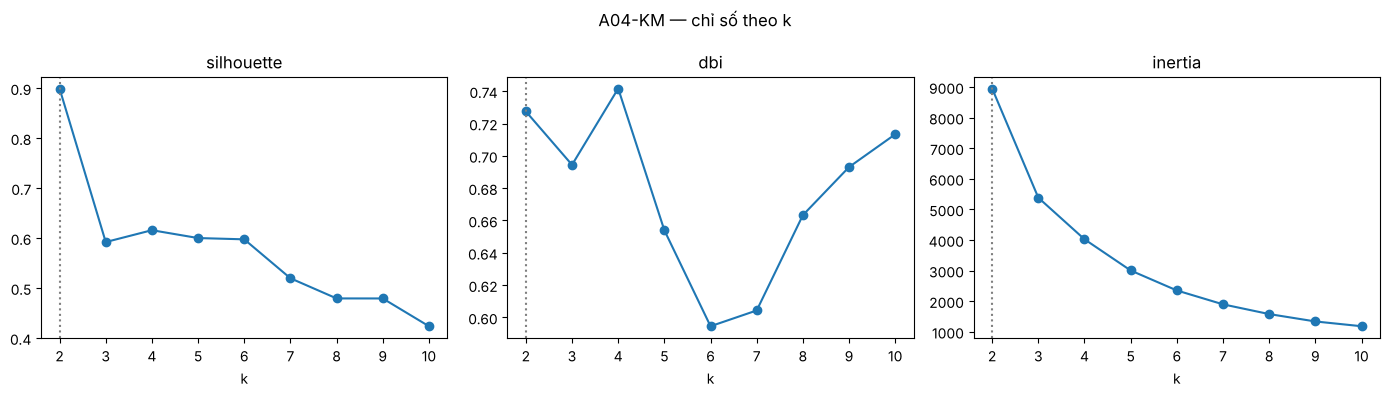

,k,silhouette,dbi,chi,inertia,min_cluster
0,2,0.8994,0.7275,1947.5218,8950.5986,24
1,3,0.5921,0.6944,3052.7379,5381.8486,24
2,4,0.6158,0.7416,3209.0488,4022.6720,12
3,5,0.6001,0.6539,3590.5747,3002.7288,3
4,6,0.5975,0.5946,3911.0777,2349.2241,2
5,7,0.5196,0.6043,4210.6281,1895.6172,2
6,8,0.4792,0.6633,4461.3181,1577.1689,2
7,9,0.4791,0.6931,4705.2422,1335.8447,2
8,10,0.4236,0.7133,4797.9135,1179.8267,2


In [4]:
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(Z)
    sizes = np.bincount(km.labels_, minlength=k)
    rows.append({"k": k, "silhouette": silhouette_score(Z, km.labels_), "dbi": davies_bouldin_score(Z, km.labels_),
                 "chi": calinski_harabasz_score(Z, km.labels_), "inertia": km.inertia_, "min_cluster": int(sizes.min())})
res = pd.DataFrame(rows)
best = res.loc[res["silhouette"].idxmax()]
print(f"Chọn k={int(best['k'])}: Silhouette={best['silhouette']:.4f}, DBI={best['dbi']:.4f}, CHI={best['chi']:.1f}, cụm nhỏ nhất={int(best['min_cluster'])}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["silhouette", "dbi", "inertia"]):
    ax.plot(res["k"], res[col], marker="o"); ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k"); ax.set_title(col)
plt.suptitle("A04-KM — chỉ số theo k"); plt.tight_layout()
plt.savefig(FIG / "kmeans_metrics_by_k.png", dpi=150); plt.show()
res.round(4)

**Nhận xét:** Silhouette cao nhất ở k=2 (0.8994); DBI 0.7275, CHI 1947.5. Cụm nhỏ nhất có 24 khách (0.55%). Cụm nhỏ nhất dưới 1% số khách: K-Means chủ yếu tách một nhóm ngoại lai khỏi khối khách đông, nên Silhouette cao không có nghĩa là phân khúc hữu ích.

## Train mô hình cuối

In [5]:
K = int(best["k"])
model = Pipeline([("prep", Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95, svd_solver="full", random_state=RANDOM_STATE)),
    ])),
                  ("kmeans", KMeans(n_clusters=K, n_init=N_INIT, random_state=RANDOM_STATE))]).fit(X.values)
labels = model["kmeans"].labels_
assert np.allclose(model["prep"].transform(X.values), Z)
print("Số khách mỗi cụm:", dict(enumerate(np.bincount(labels).tolist())))
print("Silhouette:", round(silhouette_score(Z, labels), 4), "| DBI:", round(davies_bouldin_score(Z, labels), 4))

Số khách mỗi cụm: {0: 4303, 1: 24}
Silhouette: 0.8994 | DBI: 0.7275


## Hồ sơ cụm (trên RFM gốc, trung vị)

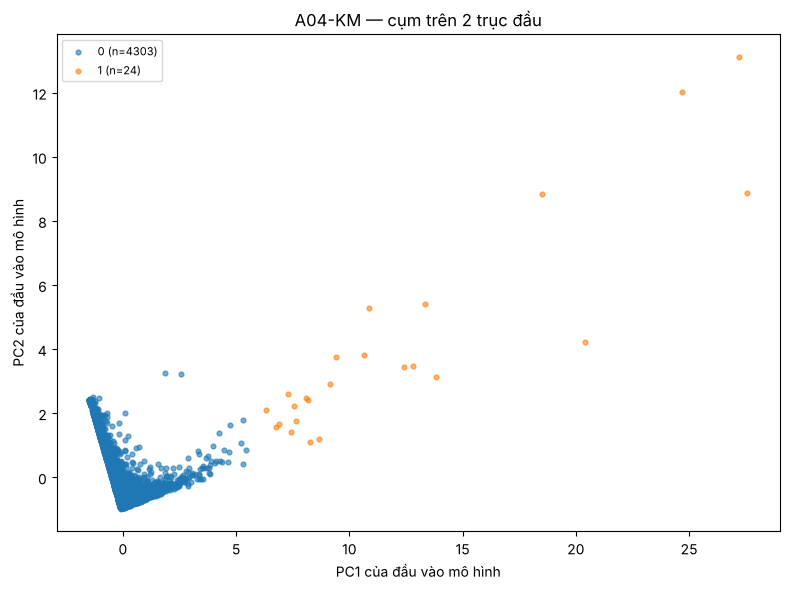

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
0,4303,52.0,2.0,655.6,99.4,76.5
1,24,3.5,55.5,58396.3,0.6,23.5


In [6]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"), Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum").round(1)

coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z) if Z.shape[1] > 2 else Z
fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(np.unique(labels)):
    m = labels == c
    ax.scatter(coords[m, 0], coords[m, 1], s=12, alpha=0.6, marker="x" if c == -1 else "o", label=f"{c} (n={m.sum()})")
ax.set_xlabel("PC1 của đầu vào mô hình"); ax.set_ylabel("PC2 của đầu vào mô hình"); ax.legend(fontsize=8)
ax.set_title("A04-KM — cụm trên 2 trục đầu")
plt.tight_layout(); plt.savefig(FIG / "kmeans_clusters_pca.png", dpi=150); plt.show()
prof

**Nhận xét:** Cụm 1 có Monetary trung vị cao nhất (58,396), gồm 24 khách (0.6%) nhưng chiếm 23.5% tổng Monetary. Cụm 0 đông nhất (99.4% khách, Recency trung vị 52 ngày). Một cụm chiếm ≥ 90% khách, nên kết quả chỉ phân biệt nhóm ngoại lai với số đông, chưa phải phân khúc khách hàng chi tiết.

## Đối chiếu với A01 (cùng tham số model)

In [ ]:

prep_parent = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Zp = prep_parent.fit_transform(X.values)
lp = KMeans(n_clusters=K, n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(Zp)
ari_parent = adjusted_rand_score(labels, lp)
same_dims = Zp.shape[1] == Z.shape[1]
same_geometry = same_dims and np.allclose(np.linalg.norm(Z[:300, None] - Z[None, :300], axis=2),
                                          np.linalg.norm(Zp[:300, None] - Zp[None, :300], axis=2), atol=1e-8)
print(f"A04: {Z.shape[1]} chiều | A01: {Zp.shape[1]} chiều")
print(f"ARI giữa nhãn A04 và nhãn A01 (cùng tham số): {ari_parent:.4f}")
print("Cùng hình học khoảng cách:", same_geometry)

A04: 3 chiều | A01: 3 chiều
ARI giữa nhãn A04 và nhãn A01 (cùng tham số): 1.0000
Cùng hình học khoảng cách: True


**Nhận xét:** ARI giữa A04 và A01 (cùng tham số) = 1.0000; số chiều đầu vào 3 so với 3. Hình học khoảng cách giống hệt và nhãn trùng 100%, nên **A04 tương đương A01** (chỉ là phép xoay PCA, không đổi kết quả).

## Lưu kết quả

In [9]:
res.to_csv(OUT / "kmeans_a04_metrics_by_k.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "kmeans_a04_labels.csv", index=False)
joblib.dump(model, "kmeans_a04_model.pkl")
params = {"experiment": "A04-KM", "features": FEATURES, "transform": None,
          "scaler": "StandardScaler", "pca": 0.95,
          "n_components": int(Z.shape[1]), "n_customers": int(len(X)),
          "pca_variance_kept": float(model["prep"]["pca"].explained_variance_ratio_.sum()),
          "k": K, "silhouette": float(silhouette_score(Z, labels)), "dbi": float(davies_bouldin_score(Z, labels)),
          "chi": float(calinski_harabasz_score(Z, labels)), "inertia": float(model["kmeans"].inertia_),
          "n_init": N_INIT,
          "ari_vs_parent_fixed_params": {"parent": "A01", "ari": float(ari_parent)}}
json.dump(params, open(OUT / "kmeans_a04_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['kmeans_a04_labels.csv', 'kmeans_a04_metrics_by_k.csv', 'kmeans_a04_params.json']


**Kết luận A04-KM:** K-Means chọn k=2 (Silhouette 0.8994) trên 3 chiều đầu vào. ARI với A01 (cùng tham số) = 1.0000. Silhouette giữa các cấu hình khác không gian đầu vào (số chiều, scaler) không so sánh trực tiếp được; dùng ARI và hồ sơ cụm trên RFM gốc để so sánh.